<a href="https://colab.research.google.com/github/Cloud-Architect-Emma/minillm-research-lab/blob/main/04_transformer_depth_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import os
import sys
import json
import time
import math
import random
import hashlib
import platform
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

try:
    torch.use_deterministic_algorithms(True)
except Exception as error:
    print("Determinism setting:", error)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0)
      if device.type == "cuda" else "Not available")

print("Environment ready")


Python: 3.13.16
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Environment ready


In [3]:

ROOT = Path("minillm_lab4")
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
CHECKPOINT_DIR = ROOT / "checkpoints"

for folder in [DATA_DIR, RESULTS_DIR, CHECKPOINT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "tiny_shakespeare.txt"

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/"
    "tinyshakespeare/input.txt"
)

if not DATA_PATH.exists():
    urlretrieve(DATA_URL, DATA_PATH)

raw_bytes = DATA_PATH.read_bytes()
text = raw_bytes.decode("utf-8")

dataset_hash = hashlib.sha256(raw_bytes).hexdigest()

chars = sorted(set(text))
vocab_size = len(chars)

stoi = {char: i for i, char in enumerate(chars)}
itos = {i: char for char, i in stoi.items()}

def encode(message):
    return [stoi[c] for c in message]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

tokens = torch.tensor(encode(text), dtype=torch.long)

n = len(tokens)
train_end = int(n * 0.90)
val_end = int(n * 0.95)

train_data = tokens[:train_end]
val_data = tokens[train_end:val_end]
test_data = tokens[val_end:]

print("Total tokens:", n)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("Test tokens:", len(test_data))
print("Vocabulary size:", vocab_size)
print("Dataset SHA256:", dataset_hash)

assert len(train_data) + len(val_data) + len(test_data) == n
assert decode(encode("Hello")) == "Hello"

print("PASS: Dataset prepared")


Total tokens: 1115394
Training tokens: 1003854
Validation tokens: 55770
Test tokens: 55770
Vocabulary size: 65
Dataset SHA256: 86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed
PASS: Dataset prepared


In [7]:

CONFIG = {
    "block_size": 32,
    "n_embd": 64,
    "n_head": 4,
    "dropout": 0.1,
    "batch_size": 32,
    "learning_rate": 3e-4,
    "weight_decay": 0.01,
    "seed": SEED,
    "depths": [2, 4, 6],
    "reference_steps": 120,
    "eval_batches": 12
}

assert CONFIG["n_embd"] % CONFIG["n_head"] == 0

print(json.dumps(CONFIG, indent=2))


{
  "block_size": 32,
  "n_embd": 64,
  "n_head": 4,
  "dropout": 0.1,
  "batch_size": 32,
  "learning_rate": 0.0003,
  "weight_decay": 0.01,
  "seed": 42,
  "depths": [
    2,
    4,
    6
  ],
  "reference_steps": 120,
  "eval_batches": 12
}


In [8]:

class AttentionHead(nn.Module):
    def __init__(self, embedding_size, head_size, context, dropout):
        super().__init__()

        self.key = nn.Linear(embedding_size, head_size, bias=False)
        self.query = nn.Linear(embedding_size, head_size, bias=False)
        self.value = nn.Linear(embedding_size, head_size, bias=False)

        self.register_buffer(
            "mask",
            torch.tril(torch.ones(context, context))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = (q @ k.transpose(-2, -1)) * (k.shape[-1] ** -0.5)

        scores = scores.masked_fill(
            self.mask[:T, :T] == 0,
            float("-inf")
        )

        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embedding_size, num_heads, context, dropout):
        super().__init__()

        head_size = embedding_size // num_heads

        self.heads = nn.ModuleList([
            AttentionHead(embedding_size, head_size, context, dropout)
            for _ in range(num_heads)
        ])

        self.proj = nn.Linear(embedding_size, embedding_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(x))


class FeedForward(nn.Module):
    def __init__(self, embedding_size, dropout):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(embedding_size, 4 * embedding_size),
            nn.ReLU(),
            nn.Linear(4 * embedding_size, embedding_size),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embedding_size, num_heads, context, dropout):
        super().__init__()

        self.attention = MultiHeadAttention(
            embedding_size, num_heads, context, dropout
        )
        self.feed_forward = FeedForward(embedding_size, dropout)

        self.ln1 = nn.LayerNorm(embedding_size)
        self.ln2 = nn.LayerNorm(embedding_size)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.feed_forward(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, depth, config, vocab_size):
        super().__init__()

        self.context = config["block_size"]

        embedding_size = config["n_embd"]

        self.token_embedding = nn.Embedding(
            vocab_size, embedding_size
        )

        self.position_embedding = nn.Embedding(
            self.context, embedding_size
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(
                embedding_size,
                config["n_head"],
                self.context,
                config["dropout"]
            )
            for _ in range(depth)
        ])

        self.final_norm = nn.LayerNorm(embedding_size)
        self.output = nn.Linear(embedding_size, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > self.context:
            raise ValueError("Sequence exceeds context window")

        positions = torch.arange(T, device=idx.device)

        x = (
            self.token_embedding(idx)
            + self.position_embedding(positions)
        )

        x = self.blocks(x)
        x = self.final_norm(x)

        logits = self.output(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


print("Reusable transformer architecture ready")


Reusable transformer architecture ready


In [9]:

model_info = []

for depth in CONFIG["depths"]:
    set_seed(SEED)

    model = MiniGPT(depth, CONFIG, vocab_size).to(device)

    parameter_count = sum(
        p.numel() for p in model.parameters()
    )

    sample = torch.randint(
        0, vocab_size,
        (2, CONFIG["block_size"]),
        device=device
    )

    with torch.no_grad():
        logits, _ = model(sample)

    assert logits.shape == (
        2, CONFIG["block_size"], vocab_size
    )

    model_info.append({
        "depth": depth,
        "parameters": parameter_count
    })

    print(
        f"{depth} blocks | "
        f"{parameter_count:,} parameters | PASS"
    )

    del model

model_info_df = pd.DataFrame(model_info)
display(model_info_df)

print("ALL ARCHITECTURES VALIDATED")


2 blocks | 110,145 parameters | PASS
4 blocks | 209,729 parameters | PASS
6 blocks | 309,313 parameters | PASS


,depth,parameters
0,2,110145
1,4,209729
2,6,309313


ALL ARCHITECTURES VALIDATED


In [10]:

parameter_lookup = dict(
    zip(
        model_info_df["depth"],
        model_info_df["parameters"]
    )
)

reference_depth = 2
reference_parameters = parameter_lookup[reference_depth]

tokens_per_step = (
    CONFIG["batch_size"] * CONFIG["block_size"]
)

compute_budget = (
    6
    * reference_parameters
    * tokens_per_step
    * CONFIG["reference_steps"]
)

experiment_plan = []

for depth in CONFIG["depths"]:
    parameters = parameter_lookup[depth]

    steps = max(
        1,
        int(
            compute_budget
            / (6 * parameters * tokens_per_step)
        )
    )

    estimated_flops = (
        6 * parameters * tokens_per_step * steps
    )

    experiment_plan.append({
        "depth": depth,
        "parameters": parameters,
        "steps": steps,
        "training_tokens": steps * tokens_per_step,
        "estimated_flops": estimated_flops
    })

plan_df = pd.DataFrame(experiment_plan)

display(plan_df)

print("Reference compute budget:", f"{compute_budget:.3e}", "FLOPs")


,depth,parameters,steps,training_tokens,estimated_flops
0,2,110145,120,122880,81207705600
1,4,209729,63,64512,81180223488
2,6,309313,42,43008,79817601024


Reference compute budget: 8.121e+10 FLOPs


In [11]:

def make_batch(data, batch_size, context, generator):
    starts = torch.randint(
        0,
        len(data) - context,
        (batch_size,),
        generator=generator
    )

    x = torch.stack([
        data[i:i + context] for i in starts
    ])

    y = torch.stack([
        data[i + 1:i + context + 1] for i in starts
    ])

    return x.to(device), y.to(device)


def make_eval_batches(data, count, seed=2026):
    generator = torch.Generator().manual_seed(seed)

    return [
        make_batch(
            data,
            CONFIG["batch_size"],
            CONFIG["block_size"],
            generator
        )
        for _ in range(count)
    ]


validation_batches = make_eval_batches(
    val_data,
    CONFIG["eval_batches"]
)

print("Fixed validation batches:", len(validation_batches))
print("PASS: Evaluation data prepared")


Fixed validation batches: 12
PASS: Evaluation data prepared


In [13]:

@torch.no_grad()
def evaluate_model(model, batches):
    model.eval()

    total_loss = 0.0

    for x, y in batches:
        _, loss = model(x, y)
        total_loss += loss.item()

    return total_loss / len(batches)


In [16]:

def run_experiment(depth, steps, seed=42):
    set_seed(seed)

    model = MiniGPT(depth, CONFIG, vocab_size).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CONFIG["learning_rate"],
        weight_decay=CONFIG["weight_decay"]
    )

    batch_generator = torch.Generator().manual_seed(seed + 1000)

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    initial_loss = evaluate_model(model, validation_batches)

    model.train()
    start = time.perf_counter()

    losses = []

    for step in range(1, steps + 1):
        x, y = make_batch(
            train_data,
            CONFIG["batch_size"],
            CONFIG["block_size"],
            batch_generator
        )

        optimizer.zero_grad(set_to_none=True)

        _, loss = model(x, y)

        loss.backward()

        optimizer.step()

        losses.append({
            "depth": depth,
            "step": step,
            "training_loss": loss.item()
        })

        if step == 1 or step % 25 == 0 or step == steps:
            print(
                f"Depth {depth} | "
                f"Step {step}/{steps} | "
                f"Training loss {loss.item():.4f}"
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    final_loss = evaluate_model(model, validation_batches)

    if device.type == "cuda":
        torch.cuda.synchronize()
        peak_memory_mb = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
        )
    else:
        peak_memory_mb = None

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    training_tokens = (
        steps * CONFIG["batch_size"] * CONFIG["block_size"]
    )

    checkpoint_path = (
        CHECKPOINT_DIR / f"minigpt_depth_{depth}.pt"
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "depth": depth,
        "config": CONFIG,
        "vocab_size": vocab_size,
        "chars": chars,
        "seed": seed,
        "steps": steps
    }, checkpoint_path)

    result = {
        "depth": depth,
        "seed": seed,
        "parameters": parameters,
        "steps": steps,
        "training_tokens": training_tokens,
        "estimated_flops": 6 * parameters * training_tokens,
        "initial_val_loss": initial_loss,
        "final_val_loss": final_loss,
        "perplexity": math.exp(final_loss),
        "training_seconds": elapsed,
        "tokens_per_second": training_tokens / elapsed,
        "peak_gpu_memory_mb": peak_memory_mb,
        "checkpoint": str(checkpoint_path)
    }

    del model, optimizer

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return result, losses


In [17]:

pilot_result, pilot_losses = run_experiment(
    depth=2,
    steps=5,
    seed=42
)

print("\nPILOT RESULTS")
for key, value in pilot_result.items():
    print(key, ":", value)


Depth 2 | Step 1/5 | Training loss 4.2817
Depth 2 | Step 5/5 | Training loss 4.1521

PILOT RESULTS
depth : 2
seed : 42
parameters : 110145
steps : 5
training_tokens : 5120
estimated_flops : 3383654400
initial_val_loss : 4.290021975835164
final_val_loss : 4.1130943695704145
perplexity : 61.13560132524376
training_seconds : 0.33475747999995065
tokens_per_second : 15294.654506303354
peak_gpu_memory_mb : 29.150390625
checkpoint : minillm_lab4/checkpoints/minigpt_depth_2.pt


In [18]:

all_results = []
all_training_logs = []

for row in experiment_plan:
    depth = int(row["depth"])
    steps = int(row["steps"])

    print("\n" + "=" * 50)
    print(f"STARTING EXPERIMENT: {depth} BLOCKS")
    print("=" * 50)

    result, logs = run_experiment(
        depth=depth,
        steps=steps,
        seed=SEED
    )

    all_results.append(result)
    all_training_logs.extend(logs)

    pd.DataFrame(all_results).to_csv(
        RESULTS_DIR / "experiment_results.csv",
        index=False
    )

    pd.DataFrame(all_training_logs).to_csv(
        RESULTS_DIR / "training_logs.csv",
        index=False
    )

    print(
        f"Finished {depth} blocks | "
        f"Validation loss: {result['final_val_loss']:.4f}"
    )

results_df = pd.DataFrame(all_results)
logs_df = pd.DataFrame(all_training_logs)

display(results_df)

print("\nALL EXPERIMENTS COMPLETE")



STARTING EXPERIMENT: 2 BLOCKS
Depth 2 | Step 1/120 | Training loss 4.2817
Depth 2 | Step 25/120 | Training loss 3.5989
Depth 2 | Step 50/120 | Training loss 3.3519
Depth 2 | Step 75/120 | Training loss 3.1953
Depth 2 | Step 100/120 | Training loss 3.1669
Depth 2 | Step 120/120 | Training loss 3.1212
Finished 2 blocks | Validation loss: 3.0401

STARTING EXPERIMENT: 4 BLOCKS
Depth 4 | Step 1/63 | Training loss 4.4261
Depth 4 | Step 25/63 | Training loss 3.5687
Depth 4 | Step 50/63 | Training loss 3.3401
Depth 4 | Step 63/63 | Training loss 3.3295
Finished 4 blocks | Validation loss: 3.2669

STARTING EXPERIMENT: 6 BLOCKS
Depth 6 | Step 1/42 | Training loss 4.4202
Depth 6 | Step 25/42 | Training loss 3.5152
Depth 6 | Step 42/42 | Training loss 3.3364
Finished 6 blocks | Validation loss: 3.3372


,depth,seed,parameters,steps,training_tokens,estimated_flops,initial_val_loss,final_val_loss,perplexity,training_seconds,tokens_per_second,peak_gpu_memory_mb,checkpoint
0,2,42,110145,120,122880,81207705600,4.290022,3.040099,20.907303,3.355603,36619.354817,29.150391,minillm_lab4/checkpoints/minigpt_depth_2.pt
1,4,42,209729,63,64512,81180223488,4.439846,3.266873,26.229194,1.917090,33651.006004,38.869141,minillm_lab4/checkpoints/minigpt_depth_4.pt
2,6,42,309313,42,43008,79817601024,4.381176,3.337197,28.140141,1.870910,22987.743576,48.587891,minillm_lab4/checkpoints/minigpt_depth_6.pt



ALL EXPERIMENTS COMPLETE


In [19]:

comparison = results_df[[
    "depth",
    "parameters",
    "steps",
    "training_tokens",
    "estimated_flops",
    "initial_val_loss",
    "final_val_loss",
    "perplexity",
    "training_seconds",
    "tokens_per_second",
    "peak_gpu_memory_mb"
]].copy()

display(comparison.round(3))


,depth,parameters,steps,training_tokens,estimated_flops,initial_val_loss,final_val_loss,perplexity,training_seconds,tokens_per_second,peak_gpu_memory_mb
0,2,110145,120,122880,81207705600,4.290,3.040,20.907,3.356,36619.355,29.150
1,4,209729,63,64512,81180223488,4.440,3.267,26.229,1.917,33651.006,38.869
2,6,309313,42,43008,79817601024,4.381,3.337,28.140,1.871,22987.744,48.588


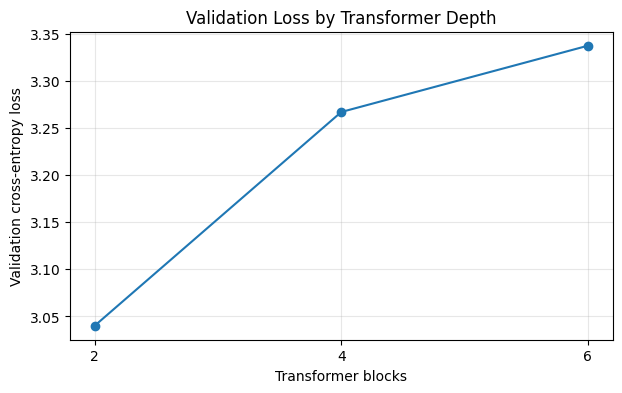

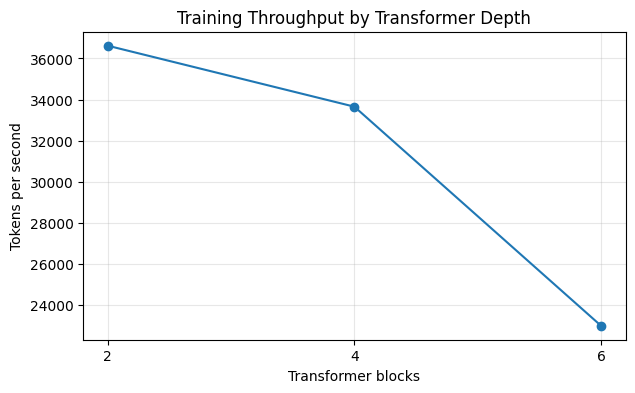

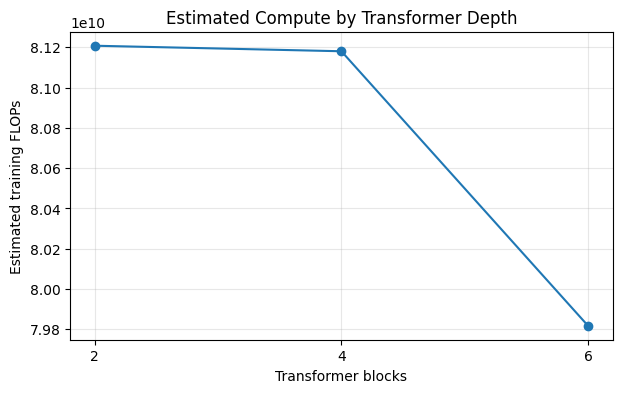

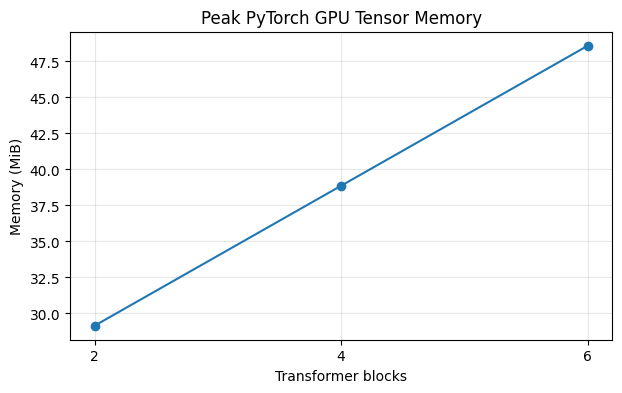

Research charts saved!


In [20]:

figures_dir = RESULTS_DIR / "figures"
figures_dir.mkdir(exist_ok=True)

chart_specs = [
    (
        "final_val_loss",
        "Validation Loss by Transformer Depth",
        "Validation cross-entropy loss",
        "validation_loss.png"
    ),
    (
        "tokens_per_second",
        "Training Throughput by Transformer Depth",
        "Tokens per second",
        "training_throughput.png"
    ),
    (
        "estimated_flops",
        "Estimated Compute by Transformer Depth",
        "Estimated training FLOPs",
        "estimated_compute.png"
    )
]

if results_df["peak_gpu_memory_mb"].notna().all():
    chart_specs.append((
        "peak_gpu_memory_mb",
        "Peak PyTorch GPU Tensor Memory",
        "Memory (MiB)",
        "gpu_memory.png"
    ))

for column, title, ylabel, filename in chart_specs:
    plt.figure(figsize=(7, 4))

    plt.plot(
        results_df["depth"],
        results_df[column],
        marker="o"
    )

    plt.title(title)
    plt.xlabel("Transformer blocks")
    plt.ylabel(ylabel)
    plt.xticks(CONFIG["depths"])
    plt.grid(True, alpha=0.3)

    plt.savefig(
        figures_dir / filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

print("Research charts saved!")


In [21]:

best_index = results_df["final_val_loss"].idxmin()
best = results_df.loc[best_index]

print("BEST MODEL UNDER THE EXPERIMENT BUDGET")
print("Transformer blocks:", int(best["depth"]))
print("Parameters:", int(best["parameters"]))
print("Validation loss:", round(best["final_val_loss"], 4))
print("Perplexity:", round(best["perplexity"], 2))
print("Training seconds:", round(best["training_seconds"], 2))

baseline = results_df.loc[
    results_df["depth"] == 2
].iloc[0]

relative_loss_change = (
    (best["final_val_loss"] - baseline["final_val_loss"])
    / baseline["final_val_loss"]
) * 100

print(
    "Validation-loss change versus 2-block baseline:",
    round(relative_loss_change, 2),
    "%"
)


BEST MODEL UNDER THE EXPERIMENT BUDGET
Transformer blocks: 2
Parameters: 110145
Validation loss: 3.0401
Perplexity: 20.91
Training seconds: 3.36
Validation-loss change versus 2-block baseline: 0.0 %


In [22]:

winning_depth = int(best["depth"])

checkpoint = torch.load(
    CHECKPOINT_DIR / f"minigpt_depth_{winning_depth}.pt",
    map_location=device,
    weights_only=True
)

winning_model = MiniGPT(
    winning_depth,
    CONFIG,
    vocab_size
).to(device)

winning_model.load_state_dict(
    checkpoint["model_state_dict"]
)

winning_model.eval()

print("Restored model depth:", winning_depth)
print("Checkpoint step:", checkpoint["steps"])


Restored model depth: 2
Checkpoint step: 120


In [23]:

@torch.no_grad()
def evaluate_test(model, data, context, batch_size=64):
    model.eval()

    total_weighted_loss = 0.0
    total_tokens = 0

    starts = list(
        range(0, len(data) - context, context)
    )

    for offset in range(0, len(starts), batch_size):
        batch_starts = starts[offset:offset + batch_size]

        x = torch.stack([
            data[i:i + context]
            for i in batch_starts
        ]).to(device)

        y = torch.stack([
            data[i + 1:i + context + 1]
            for i in batch_starts
        ]).to(device)

        _, loss = model(x, y)

        token_count = y.numel()

        total_weighted_loss += loss.item() * token_count
        total_tokens += token_count

    return total_weighted_loss / total_tokens


test_loss = evaluate_test(
    winning_model,
    test_data,
    CONFIG["block_size"]
)

test_perplexity = math.exp(test_loss)

print("Selected architecture:", winning_depth, "blocks")
print("Test loss:", round(test_loss, 4))
print("Test perplexity:", round(test_perplexity, 2))


Selected architecture: 2 blocks
Test loss: 3.084
Test perplexity: 21.85


In [24]:

metadata = {
    "project": "MiniLLM Research Lab",
    "experiment": "Transformer Depth Comparison",
    "research_question": (
        "How does transformer depth affect validation loss "
        "under an approximate fixed compute budget?"
    ),
    "seed": SEED,
    "dataset_source": DATA_URL,
    "dataset_sha256": dataset_hash,
    "split": {
        "train": 0.90,
        "validation": 0.05,
        "test": 0.05
    },
    "config": CONFIG,
    "device": str(device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if device.type == "cuda"
        else None
    ),
    "python_version": sys.version,
    "pytorch_version": torch.__version__,
    "platform": platform.platform(),
    "compute_estimate": "6 * parameters * training_tokens",
    "selected_depth": winning_depth,
    "selected_model_test_loss": test_loss,
    "selected_model_test_perplexity": test_perplexity,
    "limitations": [
        "One seed per architecture",
        "Approximate rather than measured FLOPs",
        "Different training-token counts under compute matching",
        "Small character-level dataset and model",
        "Validation loss estimated using fixed sampled batches"
    ]
}

with open(
    RESULTS_DIR / "experiment_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=2)

results_df.to_csv(
    RESULTS_DIR / "experiment_results.csv",
    index=False
)

logs_df.to_csv(
    RESULTS_DIR / "training_logs.csv",
    index=False
)

print("Metadata and results saved")


Metadata and results saved


In [25]:

assert len(results_df) == 3
assert set(results_df["depth"]) == {2, 4, 6}

assert results_df["final_val_loss"].notna().all()
assert results_df["training_seconds"].gt(0).all()
assert results_df["parameters"].gt(0).all()

assert math.isfinite(test_loss)
assert test_loss > 0

for depth in CONFIG["depths"]:
    assert (
        CHECKPOINT_DIR / f"minigpt_depth_{depth}.pt"
    ).exists()

assert (
    RESULTS_DIR / "experiment_metadata.json"
).exists()

print("ALL LAB 4 VALIDATION TESTS PASSED")


ALL LAB 4 VALIDATION TESTS PASSED


In [26]:

import shutil
from google.colab import files

shutil.make_archive(
    "minillm_lab4_results",
    "zip",
    root_dir=str(ROOT),
    base_dir="results"
)

files.download("minillm_lab4_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

equal_step_results = []

for depth in CONFIG["depths"]:
    result, _ = run_experiment(
        depth=depth,
        steps=CONFIG["reference_steps"],
        seed=123
    )

    equal_step_results.append(result)

equal_steps_df = pd.DataFrame(equal_step_results)

equal_steps_df.to_csv(
    RESULTS_DIR / "equal_steps_results.csv",
    index=False
)

display(equal_steps_df[[
    "depth",
    "steps",
    "training_tokens",
    "estimated_flops",
    "final_val_loss",
    "training_seconds"
]])


Depth 2 | Step 1/120 | Training loss 4.3627
Depth 2 | Step 25/120 | Training loss 3.6436
Depth 2 | Step 50/120 | Training loss 3.3763
Depth 2 | Step 75/120 | Training loss 3.3404
Depth 2 | Step 100/120 | Training loss 3.0853
Depth 2 | Step 120/120 | Training loss 3.0341
Depth 4 | Step 1/120 | Training loss 4.3907
Depth 4 | Step 25/120 | Training loss 3.5884
Depth 4 | Step 50/120 | Training loss 3.3537
Depth 4 | Step 75/120 | Training loss 3.2784
Depth 4 | Step 100/120 | Training loss 2.9873
Depth 4 | Step 120/120 | Training loss 2.9119
Depth 6 | Step 1/120 | Training loss 4.3058
Depth 6 | Step 25/120 | Training loss 3.4689
Depth 6 | Step 50/120 | Training loss 3.3161
Depth 6 | Step 75/120 | Training loss 3.2024
Depth 6 | Step 100/120 | Training loss 2.8962
Depth 6 | Step 120/120 | Training loss 2.8145


,depth,steps,training_tokens,estimated_flops,final_val_loss,training_seconds
0,2,120,122880,81207705600,3.049242,1.997003
1,4,120,122880,154628997120,2.926378,3.624607
2,6,120,122880,228050288640,2.842928,5.923117
